# Question 1:
 
A retail store wants to identify customers who make frequent purchases. Given the dataset below, write a code to:
1.	Group customers by their IDs.
2.	Calculate the total number of purchases per customer.
3.	Identify the top 3 frequent customers.


In [1]:
data = {'Customer_ID': [101, 102, 103, 101, 104, 102, 101, 105, 102, 103],
        'Purchase_Amount': [200, 150, 180, 220, 300, 200, 100, 400, 250, 300]}

In [2]:
import pandas as pd
df = pd.DataFrame(data)
df

,Customer_ID,Purchase_Amount
0,101,200
1,102,150
2,103,180
3,101,220
4,104,300
5,102,200
6,101,100
7,105,400
8,102,250
9,103,300


In [3]:
total = df.groupby("Customer_ID")["Purchase_Amount"].sum().reset_index()
print(f"Total Purchase per customer: \n{total}")

frequent = total.sort_values("Purchase_Amount",ascending=False).head(3)
print(F"Top 3 Frequent customers: \n{frequent}")

Total Purchase per customer: 
   Customer_ID  Purchase_Amount
0          101              520
1          102              600
2          103              480
3          104              300
4          105              400
Top 3 Frequent customers: 
   Customer_ID  Purchase_Amount
1          102              600
0          101              520
2          103              480


# Question 2:
A company tracks the daily sales of a product over a month. You are tasked with identifying any abnormal sales data using the IQR (Interquartile Range) method.


In [4]:
data = {'Day': range(1, 31),
        'Sales': [25, 30, 28, 45, 55, 60, 22, 80, 95, 120,
                  33, 29, 27, 35, 40, 50, 85, 110, 105, 92,
                  30, 34, 31, 33, 36, 42, 44, 48, 90, 200]}


In [5]:
import pandas as pd
df = pd.DataFrame(data)

***Tasks:***
1. Calculate the Q1 (25th percentile) and Q3 (75th percentile).
2. Determine the IQR.
3. Identify the Lower Bound and Upper Bound.
4. Detect and display the outliers.
5. Replace the Outliers with the Median Value.


In [6]:
# 1. Q1 and Q3 calculation
import numpy as np
q1 = np.percentile(df["Sales"],25)
q3 = np.percentile(df["Sales"],75)
print(f"Q1: {q1}, Q3: {q3}")

Q1: 31.5, Q3: 83.75


In [7]:
# 2. IQR
IQR = q3-q1
print(f"Inter Quartile Range: {IQR}")

Inter Quartile Range: 52.25


In [8]:
# 3. Lower and Upper bound
lower = q1-(1.5*IQR)
upper = q3+(1.5*IQR)

print(f"Lower Bound: {lower}, Upper Bound: {upper}")

Lower Bound: -46.875, Upper Bound: 162.125


In [9]:
# 4. Finding the Outlier
outliers = df[(df["Sales"]<lower) | (df["Sales"]>upper)]
print(f"Outliers Detected: \n{outliers}")

Outliers Detected: 
    Day  Sales
29   30    200


In [10]:
# Replacing outliers with median value
median = df["Sales"].median()

outliers = (df["Sales"]<lower) | (df["Sales"]>upper)
df["Sales"] = df["Sales"].mask(outliers,median)

print(f"Data after Replacing Outliers \n{df}")

Data after Replacing Outliers 
    Day  Sales
0     1     25
1     2     30
2     3     28
3     4     45
4     5     55
5     6     60
6     7     22
7     8     80
8     9     95
9    10    120
10   11     33
11   12     29
12   13     27
13   14     35
14   15     40
15   16     50
16   17     85
17   18    110
18   19    105
19   20     92
20   21     30
21   22     34
22   23     31
23   24     33
24   25     36
25   26     42
26   27     44
27   28     48
28   29     90
29   30     43


# Question 3:
 
A pharmaceutical company is testing the effectiveness of a new drug to reduce blood pressure. Two groups of patients were selected:

Group 1 (Treatment): Received the drug

Group 2 (Control): Received a placebo

The company wants to check if there is a significant difference in the blood pressure levels between the two groups using an Independent T-Test.


In [11]:
data = {'Group': ['Treatment']*10 + ['Control']*10,
        'Blood_Pressure': [120, 115, 118, 123, 122, 119, 124, 117, 116, 121,
                            130, 135, 140, 138, 142, 136, 139, 134, 137, 141]}
df = pd.DataFrame(data)
df

,Group,Blood_Pressure
0,Treatment,120
1,Treatment,115
2,Treatment,118
3,Treatment,123
4,Treatment,122
5,Treatment,119
6,Treatment,124
7,Treatment,117
8,Treatment,116
9,Treatment,121


Tasks:
1.	Perform an Independent T-Test.
2.	State the null and alternative hypotheses.
3.	Calculate the p-value.
4.	Conclude whether the drug has a significant effect.


In [12]:
# 1. Perform Independent T- test
from scipy.stats import ttest_rel

treatment = df[df["Group"] == 'Treatment']['Blood_Pressure']
control = df[df["Group"] == 'Control']['Blood_Pressure']

t_stat , p_value = ttest_rel(treatment,control)

2. Null and alternative hypothesis

H0 : The durg has no significant effect 

H1 : The drug has significant effect

In [13]:
# 3 . P value
print(f"T-Statistic: {t_stat}\n P-Value: {p_value}")

# 4. Conclusion 
p = 0.05
if p_value < p:
    print("Reject the null hupothesis, The drug has significant effect")
else: 
    print("Accept Null hypothesis, The drug has no significant effect")

T-Statistic: -15.322266698697408
 P-Value: 9.378009243066762e-08
Reject the null hupothesis, The drug has significant effect


# Question 4:
GlobalMart is a large retailer conducting advertisement campaigns in different regions. The company spends money on two types of advertisements: TV Ads and Social Media Ads
They want to analyze how these ads influence their sales.
Your task is to calculate the Covariance and Correlation to determine which type of ad has a stronger impact on sales.

***Tasks :***
1.	Calculate the Covariance between ad budgets and sales to measure the direction of the relationship.
2.	Calculate the Correlation to measure the strength of the relationship.
3.	Determine which type of ad is more effective for increasing sales.


In [14]:
data = {
    'Region': ['North', 'South', 'East', 'West', 'Central'],
    'TV_Ad_Budget': [200, 300, 400, 500, 600],
    'Social_Media_Budget': [150, 250, 300, 450, 500],
    'Sales': [20, 35, 50, 60, 80]
}
df = pd.DataFrame(data)
df

,Region,TV_Ad_Budget,Social_Media_Budget,Sales
0,North,200,150,20
1,South,300,250,35
2,East,400,300,50
3,West,500,450,60
4,Central,600,500,80


In [15]:
# 1. calculate covariance
tv = df["TV_Ad_Budget"].cov(df["Sales"])
social = df["Social_Media_Budget"].cov(df["Sales"])


In [16]:
# 2. Claculate correlation
cor_tv = df["TV_Ad_Budget"].corr(df["Sales"])
cor_social = df["Social_Media_Budget"].corr(df["Sales"])

In [17]:
print(f"Covariance (TV vs Sales): {tv}")
print(f"Covariance (Social Media vs Sales): {social}")
print(f"Correlation (TV vs Sales): {cor_tv}")
print(f"Correlation (Social Media vs Sales): {cor_social}")

# 3. conclusion
if cor_tv > cor_social:
    print("TV Ads have a stronger impact on Sales.")
else:
    print("TV Ads have a lower impact on Sales.")

Covariance (TV vs Sales): 3625.0
Covariance (Social Media vs Sales): 3225.0
Correlation (TV vs Sales): 0.9958640886279954
Correlation (Social Media vs Sales): 0.9724846021568381
TV Ads have a stronger impact on Sales.


# Question 5:
A company tracks the delivery time (in minutes) for its online orders. You are given the delivery times for 50 orders.

●	Calculate the mean and standard deviation of the delivery times.

●	Plot the Probability Density Function (PDF) to visualize the distribution.


In [18]:
data = [25, 30, 28, 45, 55, 60, 22, 80, 95, 120, 33, 29, 27, 35, 40, 50, 85, 110, 105, 92, 30, 34, 31, 33,
         36, 42, 44, 48, 90, 200, 20, 25, 27, 32, 38, 41, 47, 58, 62, 77, 80, 84, 90, 110, 123, 145, 150, 160]


In [19]:
# Calculate Mean and Standard Deviation
mean = np.mean(data)
std_dev = np.std(data)

print(f"Mean Delivery Time: {mean}")
print(f"Standard Deviation of Delivery Time: {std_dev}")

Mean Delivery Time: 65.0625
Standard Deviation of Delivery Time: 41.718504212759115


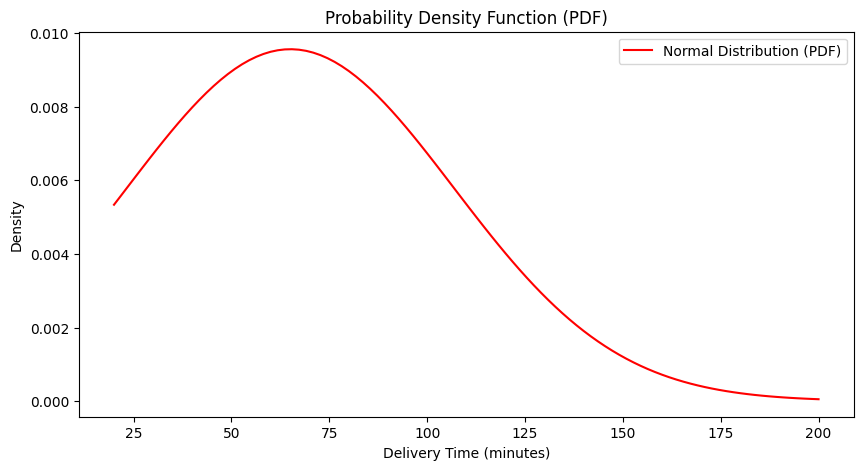

In [20]:
# Plotting PDF
import matplotlib.pyplot as plt
from scipy.stats import norm
x = np.linspace(min(data), max(data), 100)
pdf = norm.pdf(x, mean, std_dev)

plt.figure(figsize=(10, 5))
plt.plot(x, pdf, color='red', label='Normal Distribution (PDF)')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Density')
plt.title('Probability Density Function (PDF)')
plt.legend()
plt.show()